## FAQ 문서를 활용한 Golden Dataset 생성

**외부 패키지 없이** LangChain의 기본 기능만으로 테스트 데이터셋을 생성

#### 핵심 포인트:
1. **RAGAS 없이도 가능**: LangChain의 `create_agent`와 `커스텀 프롬프트`만 활용하기
2. **좋은 데이터가 핵심**: FAQ처럼 이미 Q&A 형태로 정리된 문서가 있으면 테스트셋 생성이 훨씬 용이함
3. **두 가지 방식 비교**: Chain 방식 vs Agent 방식

---

### Chain vs Agent 비교

| 특성 | Chain 방식 | Agent 방식 |
|------|-----------|------------|
| 구현 | `prompt \| model` 파이프라인 | `create_agent()` 함수 |
| 유연성 | 단순하고 예측 가능 | 도구 사용 등 확장 가능 |
| 사용 시점 | 단순 변환 작업 | 복잡한 추론이 필요할 때 |

---
### 전체 워크플로우

```
FAQ 마크다운 문서 → LLM으로 Q&A 추출 → Pydantic으로 구조화 → CSV로 저장
```


---

In [1]:
# Pydantic: LLM에 'json 형식으로 생성해줘' 라는 프롬프트를 넣어도 아웃풋이 잘 생성이 안되는 경우가 있음 (특정 output을 원한다면, pydantic 객체를 넘겨주면 됨)

In [2]:
from dotenv import load_dotenv

load_dotenv()

True

In [3]:
# pydantic 모델 설정

from pydantic import BaseModel, Field
from typing import List, Optional

# Ground Truth 모델 (단일 쌍만 가능)
class GroundTruth(BaseModel):
    question: str = Field(description="The question to be answered")
    answer: str = Field(description="The answer to the question")


class GroundTruthList(BaseModel):
    ground_truths: List[GroundTruth] = Field(description="A list of ground truth question-answer pairs")  # GroundTruth 가 여러개 들어갈 수 있도록 List로 설정

    

In [4]:
from langchain_openai import ChatOpenAI

model = ChatOpenAI(model_name="gpt-4.1", temperature=0)  # LLM 선언
model_with_pydantic = model.with_structured_output(GroundTruthList)  # model_with_pydantic.invoke()를 호출하면 GroundTruthList 객체로 반환

In [5]:
# 프롬프르 작성
from langchain_core.prompts import ChatPromptTemplate

system_prompt = """You are a helpful AI assistant that generates a list of question-answer pairs from a given FAQ document.
Make sure to generate the pairs in Korean"""

prompt = ChatPromptTemplate.from_messages([
    ("system", system_prompt),
    ("user", "Generate a list of question-answer pairs from the following FAQ document:\n{faq_document}")
])

# 프롬프트를 영어로 작성하는 이유 -> 토큰 비용 절감을 위해서임

In [6]:
from pathlib import Path

faq_path = Path(
    "../../documents/documents_with_english_titles_markdown/"
    "employee_benefits_and_welfare_faq.md"
)
faq_content = faq_path.read_text(encoding="utf-8")
faq_content

'직원 복리후생 및 복지 FAQ\n=====================\n\n1. 연차 유급 휴가 관련\n-----------------\n\nQ1: 연차 휴가는 어떻게 사용하나요?\n- A: 연차 휴가는 본인 승인을 통해 자유롭게 사용할 수 있으며, 사내 HR 시스템에서 신청 가능합니다.\n\nQ2: 연차는 어떻게 계산되나요?\n- A: 근속 연수에 따라 차등 지급되며, 1년 미만은 월 1일, 1~3년은 15일, 10년 이상은 20일입니다.\n\nQ3: 미사용 연차는 어떻게 처리되나요?\n- A: 연차는 해당 연도에 사용해야 하며, 이월은 불가합니다.\n\n2. 출산 및 육아 휴가 관련\n------------------\n\nQ4: 출산 휴가는 언제부터 사용할 수 있나요?\n- A: 출산 예정일 전후로 자유롭게 사용할 수 있으며, 최대 20일 유급으로 제공됩니다.\n\nQ5: 육아 휴가는 누구에게 적용되나요?\n- A: 모든 직원이 신청할 수 있으며, 최대 1년까지 사용할 수 있으며, 첫 3개월은 급여의 50%가 지급됩니다.\n\n3. 경조 휴가 및 지원\n--------------\n\nQ6: 경조 휴가는 어떤 경우에 사용할 수 있나요?\n- A: 본인 결혼, 자녀 출생, 부모/배우자 사망 등 경조사 사유에 따라 휴가가 부여됩니다.\n\nQ7: 경조사 지원금은 어떻게 신청하나요?\n- A: HR 시스템을 통해 신청할 수 있으며, 지원금은 지정된 계좌로 지급됩니다.\n\n4. 교육 지원\n\nQ8: 외부 교육비는 어떻게 신청하나요?\n- A: 외부 교육 프로그램 신청 후 영수증을 첨부하여 HR 시스템에 신청합니다.\n\nQ9: 온라인 교육은 어떤 플랫폼을 사용할 수 있나요?\n- A: 회사 지정 플랫폼 (Inflearn, Udemy)을 자유롭게 이용할 수 있습니다.\n\n\n5. 문화 활동 및 동호회 지원\n\nQ10: 문화의 날 지원금은 어떻게 사용하나요?\n- A: 문화 활동(영화, 공연, 스포츠) 비용으로 사용 가능하며, 월 최대 50,000원 지원

In [7]:
# 체이닝
# faq_content가 invoke()에 들어가면, 프롬프트에 faq_content가 들어가고, 그 프롬프트를 기반으로 model_with_pydantic이 GroundTruthList 객체로 반환

ground_truth_chain = prompt | model_with_pydantic # pydantic 모델과 프롬프트를 체인으로 연결
ground_truth_list = ground_truth_chain.invoke({"faq_document": faq_content})  # 프롬프트에 faq_content를 넣어주고, pydantic 모델로 반환


c:\studyhub\ai\agentic-ai\ai-agent-evaluation\.venv\Lib\site-packages\langsmith\_internal\_addressing.py:104: LangSmithBetaWarning: Addressing runs with `langsmith.address` is in beta and is enabled per workspace. A workspace without it rejects the run, so the trace is lost rather than falling back to a project. The behavior may change without notice.
  _warn_once(


In [8]:
ground_truth_list

GroundTruthList(ground_truths=[GroundTruth(question='연차 휴가는 어떻게 사용하나요?', answer='연차 휴가는 본인 승인을 통해 자유롭게 사용할 수 있으며, 사내 HR 시스템에서 신청 가능합니다.'), GroundTruth(question='연차는 어떻게 계산되나요?', answer='근속 연수에 따라 차등 지급되며, 1년 미만은 월 1일, 1~3년은 15일, 10년 이상은 20일입니다.'), GroundTruth(question='미사용 연차는 어떻게 처리되나요?', answer='연차는 해당 연도에 사용해야 하며, 이월은 불가합니다.'), GroundTruth(question='출산 휴가는 언제부터 사용할 수 있나요?', answer='출산 예정일 전후로 자유롭게 사용할 수 있으며, 최대 20일 유급으로 제공됩니다.'), GroundTruth(question='육아 휴가는 누구에게 적용되나요?', answer='모든 직원이 신청할 수 있으며, 최대 1년까지 사용할 수 있으며, 첫 3개월은 급여의 50%가 지급됩니다.'), GroundTruth(question='경조 휴가는 어떤 경우에 사용할 수 있나요?', answer='본인 결혼, 자녀 출생, 부모/배우자 사망 등 경조사 사유에 따라 휴가가 부여됩니다.'), GroundTruth(question='경조사 지원금은 어떻게 신청하나요?', answer='HR 시스템을 통해 신청할 수 있으며, 지원금은 지정된 계좌로 지급됩니다.'), GroundTruth(question='외부 교육비는 어떻게 신청하나요?', answer='외부 교육 프로그램 신청 후 영수증을 첨부하여 HR 시스템에 신청합니다.'), GroundTruth(question='온라인 교육은 어떤 플랫폼을 사용할 수 있나요?', answer='회사 지정 플랫폼 (Inflearn, Udemy)을 자유롭게 이용할 수 있습니다.'), GroundTruth(question='문화의 날 지원금은 어떻게 사용하나

#### csv 파일로 저장

In [9]:
# csv로 저장

import pandas as pd

# model_dump() : json 으로 바뀜
chain_df = pd.DataFrame([gt.model_dump() for gt in ground_truth_list.ground_truths])
chain_df.to_csv("../../documents/custom_agent_faq_testset.csv", index=False)  

In [10]:
ground_truth_list.ground_truths[0].model_dump()  # 첫번째 GroundTruth 객체를 json으로 변환

{'question': '연차 휴가는 어떻게 사용하나요?',
 'answer': '연차 휴가는 본인 승인을 통해 자유롭게 사용할 수 있으며, 사내 HR 시스템에서 신청 가능합니다.'}

### Agent

In [11]:
from langchain.agents import create_agent

agent = create_agent(
    model=model,   # pydantic 모델을 사용하지 않고, 일반 모델을 사용
    tools=[],
    response_format = GroundTruthList, 
    system_prompt = system_prompt
)

In [12]:
"""

# agent 는 List[BaseMesage] 형태로 반환
# BaseMesage

# 1. Human
# 2. AI
# 3. Tool
# 4. System

"""

'\n\n# agent 는 List[BaseMesage] 형태로 반환\n# BaseMesage\n\n# 1. Human\n# 2. AI\n# 3. Tool\n# 4. System\n\n'

In [14]:
from langchain_core.messages import HumanMessage


ground_truth_from_agent = agent.invoke({
    "messages": [HumanMessage(content=f"Generate a list of question-answer pairs from the following FAQ document:\n\n{faq_content}")]
}) 


In [15]:
ground_truth_from_agent

{'messages': [HumanMessage(content='Generate a list of question-answer pairs from the following FAQ document:\n\n직원 복리후생 및 복지 FAQ\n=====================\n\n1. 연차 유급 휴가 관련\n-----------------\n\nQ1: 연차 휴가는 어떻게 사용하나요?\n- A: 연차 휴가는 본인 승인을 통해 자유롭게 사용할 수 있으며, 사내 HR 시스템에서 신청 가능합니다.\n\nQ2: 연차는 어떻게 계산되나요?\n- A: 근속 연수에 따라 차등 지급되며, 1년 미만은 월 1일, 1~3년은 15일, 10년 이상은 20일입니다.\n\nQ3: 미사용 연차는 어떻게 처리되나요?\n- A: 연차는 해당 연도에 사용해야 하며, 이월은 불가합니다.\n\n2. 출산 및 육아 휴가 관련\n------------------\n\nQ4: 출산 휴가는 언제부터 사용할 수 있나요?\n- A: 출산 예정일 전후로 자유롭게 사용할 수 있으며, 최대 20일 유급으로 제공됩니다.\n\nQ5: 육아 휴가는 누구에게 적용되나요?\n- A: 모든 직원이 신청할 수 있으며, 최대 1년까지 사용할 수 있으며, 첫 3개월은 급여의 50%가 지급됩니다.\n\n3. 경조 휴가 및 지원\n--------------\n\nQ6: 경조 휴가는 어떤 경우에 사용할 수 있나요?\n- A: 본인 결혼, 자녀 출생, 부모/배우자 사망 등 경조사 사유에 따라 휴가가 부여됩니다.\n\nQ7: 경조사 지원금은 어떻게 신청하나요?\n- A: HR 시스템을 통해 신청할 수 있으며, 지원금은 지정된 계좌로 지급됩니다.\n\n4. 교육 지원\n\nQ8: 외부 교육비는 어떻게 신청하나요?\n- A: 외부 교육 프로그램 신청 후 영수증을 첨부하여 HR 시스템에 신청합니다.\n\nQ9: 온라인 교육은 어떤 플랫폼을 사용할 수 있나요?\n- A: 회사 지정 플랫폼 (Inflearn, Udemy)을 자유롭게 이용할 수 있

In [16]:
"""
** 생성된 답변
{'messages': [HumanMessage(content='Generate a list of question-answer pairs from the following FAQ document:\n\n직원 복리후생 및 복지 FAQ\n=====================\n\n1. 연차 유급 휴가 관련\n-----------------\n\nQ1: 연차 휴가는 어떻게 사용하나요?\n- A: 연차 휴가는 본인 승인을 통해 자유롭게 사용할 수 있으며, 사내 HR 시스템에서 신청 가능합니다.\n\nQ2: 연차는 어떻게 계산되나요?\n- A: 근속 연수에 따라 차등 지급되며, 1년 미만은 월 1일, 1~3년은 15일, 10년 이상은 20일입니다.\n\nQ3: 미사용 연차는 어떻게 처리되나요?\n- A: 연차는 해당 연도에 사용해야 하며, 이월은 불가합니다.\n\n2. 출산 및 육아 휴가 관련\n------------------\n\nQ4: 출산 휴가는 언제부터 사용할 수 있나요?\n- A: 출산 예정일 전후로 자유롭게 사용할 수 있으며, 최대 20일 유급으로 제공됩니다.\n\nQ5: 육아 휴가는 누구에게 적용되나요?\n- A: 모든 직원이 신청할 수 있으며, 최대 1년까지 사용할 수 있으며, 첫 3개월은 급여의 50%가 지급됩니다.\n\n3. 경조 휴가 및 지원\n--------------\n\nQ6: 경조 휴가는 어떤 경우에 사용할 수 있나요?\n- A: 본인 결혼, 자녀 출생, 부모/배우자 사망 등 경조사 사유에 따라 휴가가 부여됩니다.\n\nQ7: 경조사 지원금은 어떻게 신청하나요?\n- A: HR 시스템을 통해 신청할 수 있으며, 지원금은 지정된 계좌로 지급됩니다.\n\n4. 교육 지원\n\nQ8: 외부 교육비는 어떻게 신청하나요?\n- A: 외부 교육 프로그램 신청 후 영수증을 첨부하여 HR 시스템에 신청합니다.\n\nQ9: 온라인 교육은 어떤 플랫폼을 사용할 수 있나요?\n- A: 회사 지정 플랫폼 (Inflearn, Udemy)을 자유롭게 이용할 수 있습니다.\n\n\n5. 문화 활동 및 동호회 지원\n\nQ10: 문화의 날 지원금은 어떻게 사용하나요?\n- A: 문화 활동(영화, 공연, 스포츠) 비용으로 사용 가능하며, 월 최대 50,000원 지원됩니다.\n\nQ11: 동호회 지원금은 어떻게 신청하나요?\n- A: 사전에 등록된 동호회 활동에 한해 월 최대 100,000원까지 지원됩니다.\n\n\n6. 기타 복지 혜택\n\nQ12: 통신비 지원은 어떻게 받을 수 있나요?\n- A: 매월 50,000원이 급여와 함께 지급됩니다.\n\nQ13: 기념일 선물은 어떤 종류로 제공되나요?\n- A: 생일에는 기념품, 입사 기념일에는 기념 타월이 제공됩니다.\n\n\n7. 문의 및 기타\n\nQ14: 복리후생 관련 문의는 어디로 하면 되나요?\n- A: HR 담당자 김지현 (이메일: kimjh@company.com, 전화번호: 02-1234-5678)에게 문의 가능합니다.', additional_kwargs={}, response_metadata={}, id='fda305a3-c30e-485e-be5a-6904e5ba0649'),
  AIMessage(content='{"ground_truths":[{"question":"연차 휴가는 어떻게 사용하나요?","answer":"연차 휴가는 본인 승인을 통해 자유롭게 사용할 수 있으며, 사내 HR 시스템에서 신청 가능합니다."},{"question":"연차는 어떻게 계산되나요?","answer":"근속 연수에 따라 차등 지급되며, 1년 미만은 월 1일, 1~3년은 15일, 10년 이상은 20일입니다."},{"question":"미사용 연차는 어떻게 처리되나요?","answer":"연차는 해당 연도에 사용해야 하며, 이월은 불가합니다."},{"question":"출산 휴가는 언제부터 사용할 수 있나요?","answer":"출산 예정일 전후로 자유롭게 사용할 수 있으며, 최대 20일 유급으로 제공됩니다."},{"question":"육아 휴가는 누구에게 적용되나요?","answer":"모든 직원이 신청할 수 있으며, 최대 1년까지 사용할 수 있으며, 첫 3개월은 급여의 50%가 지급됩니다."},{"question":"경조 휴가는 어떤 경우에 사용할 수 있나요?","answer":"본인 결혼, 자녀 출생, 부모/배우자 사망 등 경조사 사유에 따라 휴가가 부여됩니다."},{"question":"경조사 지원금은 어떻게 신청하나요?","answer":"HR 시스템을 통해 신청할 수 있으며, 지원금은 지정된 계좌로 지급됩니다."},{"question":"외부 교육비는 어떻게 신청하나요?","answer":"외부 교육 프로그램 신청 후 영수증을 첨부하여 HR 시스템에 신청합니다."},{"question":"온라인 교육은 어떤 플랫폼을 사용할 수 있나요?","answer":"회사 지정 플랫폼 (Inflearn, Udemy)을 자유롭게 이용할 수 있습니다."},{"question":"문화의 날 지원금은 어떻게 사용하나요?","answer":"문화 활동(영화, 공연, 스포츠) 비용으로 사용 가능하며, 월 최대 50,000원 지원됩니다."},{"question":"동호회 지원금은 어떻게 신청하나요?","answer":"사전에 등록된 동호회 활동에 한해 월 최대 100,000원까지 지원됩니다."},{"question":"통신비 지원은 어떻게 받을 수 있나요?","answer":"매월 50,000원이 급여와 함께 지급됩니다."},{"question":"기념일 선물은 어떤 종류로 제공되나요?","answer":"생일에는 기념품, 입사 기념일에는 기념 타월이 제공됩니다."},{"question":"복리후생 관련 문의는 어디로 하면 되나요?","answer":"HR 담당자 김지현 (이메일: kimjh@company.com, 전화번호: 02-1234-5678)에게 문의 가능합니다."}]}', additional_kwargs={'parsed': None, 'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 593, 'prompt_tokens': 835, 'total_tokens': 1428, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_9dba188b17', 'id': 'chatcmpl-EeLofdWm7meS7gCCzMAaYltMSxPtl', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a18828-0bf5-74d7-9380-78451fb89104-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 835, 'output_tokens': 593, 'total_tokens': 1428, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})],
 'structured_response': GroundTruthList(ground_truths=[GroundTruth(question='연차 휴가는 어떻게 사용하나요?', answer='연차 휴가는 본인 승인을 통해 자유롭게 사용할 수 있으며, 사내 HR 시스템에서 신청 가능합니다.'), GroundTruth(question='연차는 어떻게 계산되나요?', answer='근속 연수에 따라 차등 지급되며, 1년 미만은 월 1일, 1~3년은 15일, 10년 이상은 20일입니다.'), GroundTruth(question='미사용 연차는 어떻게 처리되나요?', answer='연차는 해당 연도에 사용해야 하며, 이월은 불가합니다.'), GroundTruth(question='출산 휴가는 언제부터 사용할 수 있나요?', answer='출산 예정일 전후로 자유롭게 사용할 수 있으며, 최대 20일 유급으로 제공됩니다.'), GroundTruth(question='육아 휴가는 누구에게 적용되나요?', answer='모든 직원이 신청할 수 있으며, 최대 1년까지 사용할 수 있으며, 첫 3개월은 급여의 50%가 지급됩니다.'), GroundTruth(question='경조 휴가는 어떤 경우에 사용할 수 있나요?', answer='본인 결혼, 자녀 출생, 부모/배우자 사망 등 경조사 사유에 따라 휴가가 부여됩니다.'), GroundTruth(question='경조사 지원금은 어떻게 신청하나요?', answer='HR 시스템을 통해 신청할 수 있으며, 지원금은 지정된 계좌로 지급됩니다.'), GroundTruth(question='외부 교육비는 어떻게 신청하나요?', answer='외부 교육 프로그램 신청 후 영수증을 첨부하여 HR 시스템에 신청합니다.'), GroundTruth(question='온라인 교육은 어떤 플랫폼을 사용할 수 있나요?', answer='회사 지정 플랫폼 (Inflearn, Udemy)을 자유롭게 이용할 수 있습니다.'), GroundTruth(question='문화의 날 지원금은 어떻게 사용하나요?', answer='문화 활동(영화, 공연, 스포츠) 비용으로 사용 가능하며, 월 최대 50,000원 지원됩니다.'), GroundTruth(question='동호회 지원금은 어떻게 신청하나요?', answer='사전에 등록된 동호회 활동에 한해 월 최대 100,000원까지 지원됩니다.'), GroundTruth(question='통신비 지원은 어떻게 받을 수 있나요?', answer='매월 50,000원이 급여와 함께 지급됩니다.'), GroundTruth(question='기념일 선물은 어떤 종류로 제공되나요?', answer='생일에는 기념품, 입사 기념일에는 기념 타월이 제공됩니다.'), GroundTruth(question='복리후생 관련 문의는 어디로 하면 되나요?', answer='HR 담당자 김지현 (이메일: kimjh@company.com, 전화번호: 02-1234-5678)에게 문의 가능합니다.')])}
"""

'\n** 생성된 답변\n{\'messages\': [HumanMessage(content=\'Generate a list of question-answer pairs from the following FAQ document:\n\n직원 복리후생 및 복지 FAQ\n=====================\n\n1. 연차 유급 휴가 관련\n-----------------\n\nQ1: 연차 휴가는 어떻게 사용하나요?\n- A: 연차 휴가는 본인 승인을 통해 자유롭게 사용할 수 있으며, 사내 HR 시스템에서 신청 가능합니다.\n\nQ2: 연차는 어떻게 계산되나요?\n- A: 근속 연수에 따라 차등 지급되며, 1년 미만은 월 1일, 1~3년은 15일, 10년 이상은 20일입니다.\n\nQ3: 미사용 연차는 어떻게 처리되나요?\n- A: 연차는 해당 연도에 사용해야 하며, 이월은 불가합니다.\n\n2. 출산 및 육아 휴가 관련\n------------------\n\nQ4: 출산 휴가는 언제부터 사용할 수 있나요?\n- A: 출산 예정일 전후로 자유롭게 사용할 수 있으며, 최대 20일 유급으로 제공됩니다.\n\nQ5: 육아 휴가는 누구에게 적용되나요?\n- A: 모든 직원이 신청할 수 있으며, 최대 1년까지 사용할 수 있으며, 첫 3개월은 급여의 50%가 지급됩니다.\n\n3. 경조 휴가 및 지원\n--------------\n\nQ6: 경조 휴가는 어떤 경우에 사용할 수 있나요?\n- A: 본인 결혼, 자녀 출생, 부모/배우자 사망 등 경조사 사유에 따라 휴가가 부여됩니다.\n\nQ7: 경조사 지원금은 어떻게 신청하나요?\n- A: HR 시스템을 통해 신청할 수 있으며, 지원금은 지정된 계좌로 지급됩니다.\n\n4. 교육 지원\n\nQ8: 외부 교육비는 어떻게 신청하나요?\n- A: 외부 교육 프로그램 신청 후 영수증을 첨부하여 HR 시스템에 신청합니다.\n\nQ9: 온라인 교육은 어떤 플랫폼을 사용할 수 있나요?\n- A: 회사 지정 플랫폼 (Inflearn, Ude

In [17]:
# csv 파일로 변환

agent_df = pd.DataFrame([gt.model_dump() for gt in ground_truth_from_agent['structured_response'].ground_truths])
agent_df.to_csv("../../documents/custom_agent_faq_testset_from_agent.csv", index=False)  # csv로 저장

#### insights
---
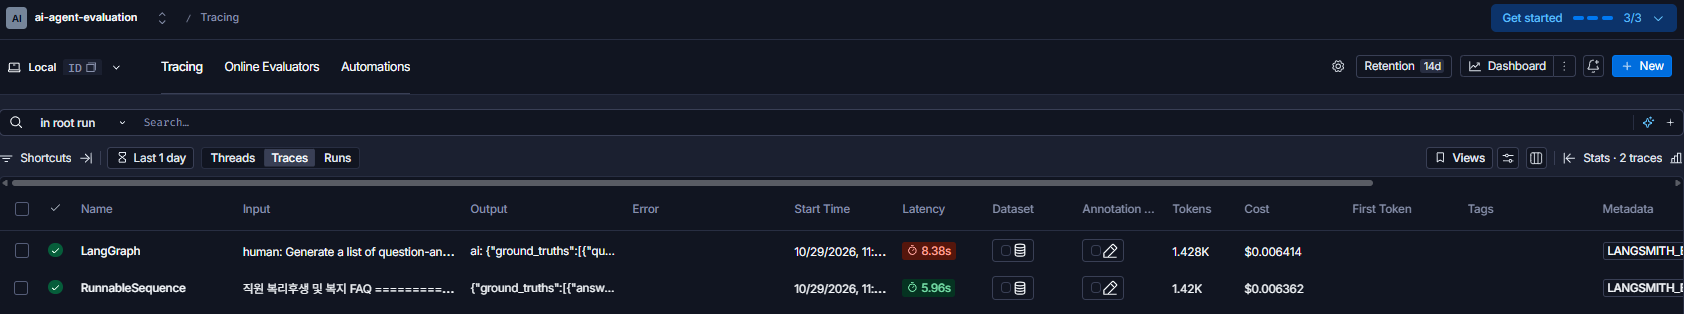

```text
1. Agent 의 효율이 좋아짐 : RunnableSequence & Langgraph Agent 토큰 비용에 큰 차이가 없다
2. agent 내부 인자 중에서 `tool = []` : 일반적으로 에이전트가 tool 선택을 시도하면서 토큰을 많이 잡아먹는다. (Langchain 에서 최적화 작업에 들어갔을 가능성이 높음)
```